In [1]:
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config

from src.train_models import (
    load_train_val_data,
    build_model_registry,
    train_and_evaluate_models,
    persistence_baseline,
)

from src.metrics import build_comparison_table

cfg = load_config(
    PROJECT_ROOT / "config.toml",
    PROJECT_ROOT,
)

print("Projekt:", PROJECT_ROOT)
print("Träningsdata:", cfg.train_processed)
print("Valideringsdata:", cfg.val_processed)

Projekt: c:\Users\Victoria\DS\Grupparbete\predicting_air_quality
Träningsdata: c:\Users\Victoria\DS\Grupparbete\predicting_air_quality\data\processed\train_processed_2023-05-26_2025-12-31.csv
Valideringsdata: c:\Users\Victoria\DS\Grupparbete\predicting_air_quality\data\processed\val_processed_2026-01-01_2026-05-31.csv


In [2]:
X_train, y_train, X_val, y_val = load_train_val_data(
    train_path=cfg.train_processed,
    val_path=cfg.val_processed,
    features=cfg.features,
    target=cfg.target_column,
)

print("Träningsdata:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValideringsdata:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nFeatures:")
print(X_train.columns.tolist())

Träningsdata:
X_train: (21555, 12)
y_train: (21555,)

Valideringsdata:
X_val: (3562, 12)
y_val: (3562,)

Features:
['pm25', 'Lufttemperatur', 'vind_sin', 'vind_cos', 'Vindhastighet', 'Relativ luftfuktighet', 'Nederbördsmängd', 'timme_sin', 'timme_cos', 'helg', 'helg_timme_sin', 'helg_timme_cos']


## Vilket PM2.5-värde motsvarar 90:e percentilen?
==> Gemensam definition av höga värden. 

In [4]:
high_pm25_threshold = y_train.quantile(0.90)

print(f"90:e percentilen: {high_pm25_threshold:.2f} µg/m³")

print(
    "Antal höga värden i träningsdata:",
    (y_train >= high_pm25_threshold).sum()
)

print(
    "Antal höga värden i valideringsdata:",
    (y_val >= high_pm25_threshold).sum()
)

train_high_share = (y_train >= high_pm25_threshold).mean() * 100
val_high_share = (y_val >= high_pm25_threshold).mean() * 100

print(f"Andel höga värden – träning: {train_high_share:.1f} %")
print(f"Andel höga värden – validering: {val_high_share:.1f} %")

90:e percentilen: 14.42 µg/m³
Antal höga värden i träningsdata: 2156
Antal höga värden i valideringsdata: 616
Andel höga värden – träning: 10.0 %
Andel höga värden – validering: 17.3 %


### Träna och utvärdera modellerna

In [5]:
import inspect

print(inspect.signature(train_and_evaluate_models))

(models, X_train, y_train, X_val, y_val)


In [7]:
models = build_model_registry(cfg.random_state)

results_df, trained_models = train_and_evaluate_models(
    models,
    X_train,
    y_train,
    X_val,
    y_val
)

display(results_df.round(3))

High PM2.5 threshold: 14.42 µg/m³
Tränar Linear Regression...
Tränar Ridge Regression...
Tränar Random Forest...
Tränar HistGradientBoosting...
Tränar SVR...
Tränar LightGBM...
Tränar XGBoost...


,Modell,Train MAE,Train RMSE,Train R²,Train Bias,Train High PM2.5 MAE,Train High PM2.5 Bias,Train High PM2.5 Count,Validation MAE,Validation RMSE,Validation R²,Validation Bias,Validation High PM2.5 MAE,Validation High PM2.5 Bias,Validation High PM2.5 Count
0,SVR,2.275,3.754,0.649,-0.465,6.711,-5.981,2156,2.910,4.453,0.711,-0.816,6.764,-5.784,616
1,HistGradientBoosting,2.068,3.056,0.767,0.005,4.851,-3.870,2156,2.971,4.557,0.697,-0.184,6.611,-4.106,616
2,LightGBM,2.063,3.037,0.770,0.000,4.829,-3.836,2156,2.978,4.569,0.695,-0.118,6.591,-3.809,616
3,Linear Regression,2.509,3.910,0.619,-0.000,6.663,-5.397,2156,2.991,4.459,0.710,-0.155,6.399,-4.902,616
4,Ridge Regression,2.509,3.910,0.619,-0.000,6.664,-5.398,2156,2.991,4.459,0.710,-0.155,6.399,-4.902,616
5,Random Forest,0.806,1.267,0.960,0.044,1.970,-1.503,2156,3.098,4.642,0.686,0.129,6.421,-3.705,616
6,XGBoost,1.613,2.325,0.865,-0.000,3.239,-2.542,2156,3.230,4.935,0.645,-0.071,7.027,-3.968,616


In [8]:
# Generell prestanda – sorterad efter lägst MAE
general_cols = [
    "Modell",
    "Validation MAE",
    "Validation RMSE",
    "Validation R²",
    "Validation Bias",
]

display(
    results_df[general_cols]
    .sort_values("Validation MAE")
    .round(3)
)

# Höga PM2.5-värden – sorterad efter lägst MAE
high_cols = [
    "Modell",
    "Validation High PM2.5 MAE",
    "Validation High PM2.5 Bias",
]

display(
    results_df[high_cols]
    .sort_values("Validation High PM2.5 MAE")
    .round(3)
)

,Modell,Validation MAE,Validation RMSE,Validation R²,Validation Bias
0,SVR,2.910,4.453,0.711,-0.816
1,HistGradientBoosting,2.971,4.557,0.697,-0.184
2,LightGBM,2.978,4.569,0.695,-0.118
3,Linear Regression,2.991,4.459,0.710,-0.155
4,Ridge Regression,2.991,4.459,0.710,-0.155
5,Random Forest,3.098,4.642,0.686,0.129
6,XGBoost,3.230,4.935,0.645,-0.071


,Modell,Validation High PM2.5 MAE,Validation High PM2.5 Bias
3,Linear Regression,6.399,-4.902
4,Ridge Regression,6.399,-4.902
5,Random Forest,6.421,-3.705
2,LightGBM,6.591,-3.809
1,HistGradientBoosting,6.611,-4.106
0,SVR,6.764,-5.784
6,XGBoost,7.027,-3.968


## Analys av modellernas prestanda

Modellerna har utvärderats på valideringsdata med MAE, RMSE, R² och Bias för att jämföra deras förmåga att förutsäga PM2.5 sex timmar framåt.

| Modell | Bedömning |
|---|---|
| **SVR** | Bäst övergripande prestanda, men störst underskattning totalt. |
| **HistGradientBoosting / LightGBM** | Näst lägst MAE och relativt låg Bias. |
| **Linear Regression / Ridge** | Nästan lika bra totalt och bäst precision vid höga PM2.5-värden. |
| **Random Forest** | Tecken på överanpassning. |
| **XGBoost** | Lägst absolut Bias totalt, men störst prognosfel. |

### Slutsatser

SVR har bäst övergripande prestanda med lägst MAE (2,910) och högst R² (0,711), men uppvisar samtidigt störst systematisk underskattning totalt.

HistGradientBoosting och LightGBM följer tätt efter med MAE på 2,971 respektive 2,978. Båda har betydligt lägre Bias än SVR.

Vid höga PM2.5-koncentrationer (≥14,42 µg/m³) presterar Linear Regression och Ridge bäst (MAE 6,399), medan samtliga modeller tenderar att underskatta höga värden, där Random Forest uppvisar lägst absolut Bias (−3,705).

Random Forest visar tecken på överanpassning och XGBoost har störst prognosfel totalt.

**Slutsats:** SVR, HistGradientBoosting, LightGBM och Linear Regression är intressanta kandidater för fortsatt utvärdering. Innan slutligt modellval behöver modellerna jämföras med persistence baseline och skillnaderna analyseras vidare.

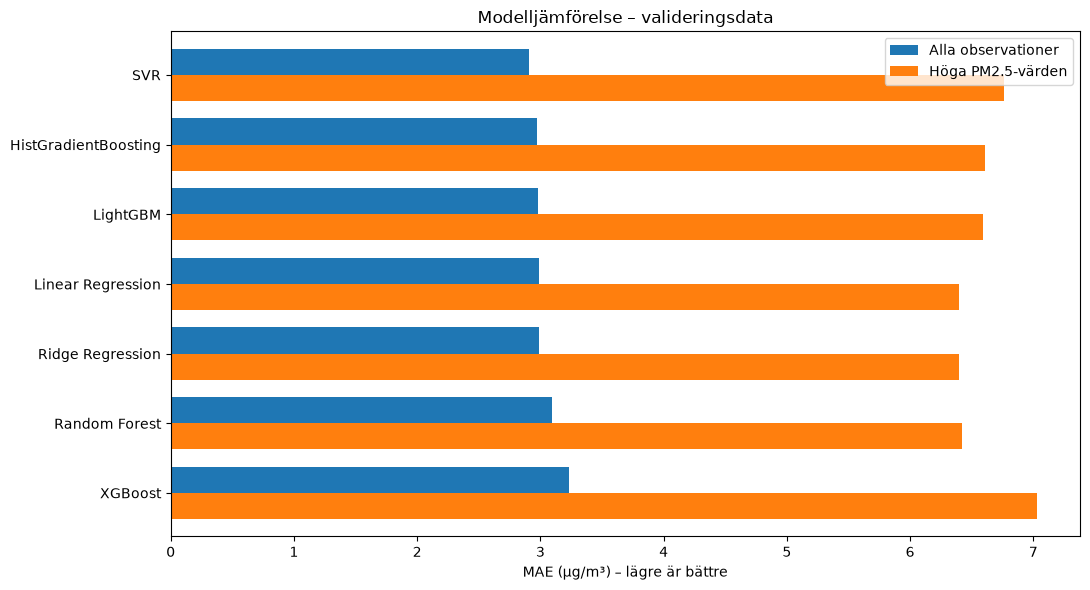

In [9]:
import matplotlib.pyplot as plt

plot_df = results_df.set_index("Modell")[
    ["Validation MAE", "Validation High PM2.5 MAE"]
].sort_values("Validation MAE")

ax = plot_df.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.75
)

ax.invert_yaxis()
ax.set_xlabel("MAE (µg/m³) – lägre är bättre")
ax.set_ylabel("")
ax.set_title("Modelljämförelse – valideringsdata")
ax.legend(["Alla observationer", "Höga PM2.5-värden"])

plt.tight_layout()
plt.show()

In [13]:
baseline_train_metrics, baseline_val_metrics = persistence_baseline(
    X_train,
    y_train,
    X_val,
    y_val
)

baseline_df = pd.DataFrame(
    [baseline_train_metrics, baseline_val_metrics],
    index=["Träning", "Validering"]
)

display(baseline_df.round(3))

,MAE,RMSE,R2,Bias,High PM2.5 MAE,High PM2.5 Bias,High PM2.5 Count
Träning,2.621,4.177,0.565,-0.020,6.448,-3.04,2156
Validering,3.108,4.703,0.677,0.017,6.122,-2.00,616


### MAE och procentuell förbättring jämfört med persistence baseline

In [14]:
comparison_pct = results_df[
    ["Modell", "Validation MAE", "Validation High PM2.5 MAE"]
].copy()

comparison_pct["Förbättring totalt (%)"] = (
    (baseline_val_metrics["MAE"] - comparison_pct["Validation MAE"])
    / baseline_val_metrics["MAE"] * 100
)

comparison_pct["Förbättring höga PM2.5 (%)"] = (
    (baseline_val_metrics["High PM2.5 MAE"] - comparison_pct["Validation High PM2.5 MAE"])
    / baseline_val_metrics["High PM2.5 MAE"] * 100
)

comparison_pct = comparison_pct.sort_values(
    "Förbättring totalt (%)", ascending=False
)

display(comparison_pct.round(2))

,Modell,Validation MAE,Validation High PM2.5 MAE,Förbättring totalt (%),Förbättring höga PM2.5 (%)
0,SVR,2.91,6.76,6.38,-10.49
1,HistGradientBoosting,2.97,6.61,4.43,-7.98
2,LightGBM,2.98,6.59,4.20,-7.66
3,Linear Regression,2.99,6.40,3.78,-4.52
4,Ridge Regression,2.99,6.40,3.78,-4.53
5,Random Forest,3.10,6.42,0.33,-4.88
6,XGBoost,3.23,7.03,-3.92,-14.79


### Jämförelse med persistence baseline

Samtliga modeller utom XGBoost uppvisar lägre MAE än persistence baseline på hela valideringsmängden. SVR ger störst förbättring med 6,4 % lägre MAE.

Vid höga PM2.5-koncentrationer (≥14,42 µg/m³) är däremot persistence baseline bättre än samtliga maskininlärningsmodeller. SVR, som presterar bäst totalt, har 10,5 % högre MAE än baseline vid höga koncentrationer.

Resultaten visar att mer avancerade modeller inte nödvändigtvis ger bättre prognoser, särskilt vid höga föroreningsnivåer.

**Slutsats:** SVR är den starkaste kandidaten utifrån generell MAE, men ingen av modellerna förbättrar prognoserna vid höga PM2.5-värden jämfört med baseline. Detta behöver beaktas vid det slutliga modellvalet.

In [15]:
svr_model = trained_models["SVR"]

y_pred_svr = svr_model.predict(X_val)

errors_df = pd.DataFrame({
    "Verkligt PM2.5": y_val.to_numpy(),
    "Prognos SVR": y_pred_svr
})

errors_df["Fel"] = (
    errors_df["Prognos SVR"] - errors_df["Verkligt PM2.5"]
)

errors_df["Absolut fel"] = errors_df["Fel"].abs()

display(errors_df.head(10).round(2))

,Verkligt PM2.5,Prognos SVR,Fel,Absolut fel
0,3.76,26.92,23.16,23.16
1,1.89,11.03,9.14,9.14
2,3.29,8.25,4.96,4.96
3,3.09,7.91,4.82,4.82
4,2.35,4.62,2.27,2.27
5,2.30,5.37,3.07,3.07
6,2.69,5.17,2.48,2.48
7,2.07,4.05,1.98,1.98
8,2.26,4.87,2.61,2.61
9,3.02,4.01,0.99,0.99


In [16]:
display(
    errors_df.sort_values(
        "Absolut fel", ascending=False
    ).head(15).round(2)
)

,Verkligt PM2.5,Prognos SVR,Fel,Absolut fel
504,47.40,9.07,-38.33,38.33
503,41.70,11.21,-30.49,30.49
1921,37.60,10.08,-27.52,27.52
1600,56.50,29.57,-26.93,26.93
1918,39.30,13.01,-26.29,26.29
931,41.30,15.14,-26.16,26.16
932,42.50,16.71,-25.79,25.79
1920,34.00,10.12,-23.88,23.88
1917,40.30,16.54,-23.76,23.76
505,35.70,12.09,-23.61,23.61


### Spridningsdiagram

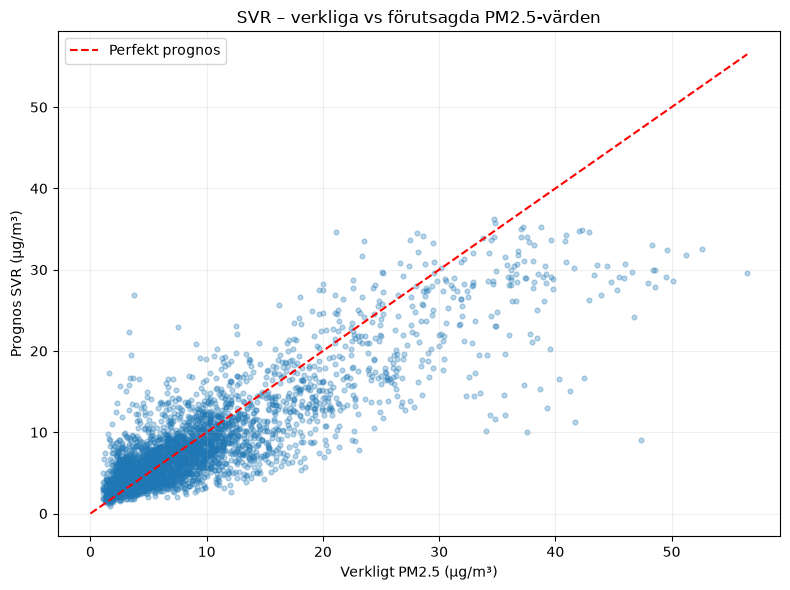

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    errors_df["Verkligt PM2.5"],
    errors_df["Prognos SVR"],
    alpha=0.3,
    s=12
)

max_value = max(
    errors_df["Verkligt PM2.5"].max(),
    errors_df["Prognos SVR"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    label="Perfekt prognos"
)

plt.xlabel("Verkligt PM2.5 (µg/m³)")
plt.ylabel("Prognos SVR (µg/m³)")
plt.title("SVR – verkliga vs förutsagda PM2.5-värden")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Analys av SVR:s prognosfel

Spridningsdiagrammet visar att SVR tenderar att överskatta låga PM2.5-koncentrationer och underskatta höga koncentrationer. Vid verkliga värden över cirka 30 µg/m³ ligger majoriteten av prognoserna under den ideala prognoslinjen.

Detta överensstämmer med modellens negativa Bias (−5,784 µg/m³) vid höga PM2.5-värden. Modellen fångar den övergripande variationen men har svårt att förutsäga de högsta koncentrationerna.

Detta är viktigt att ha i åtanke vid tolkningen av prognoserna, eftersom det påverkar vilka slutsatser som kan dras och vilka användningsområden modellen är lämplig för.

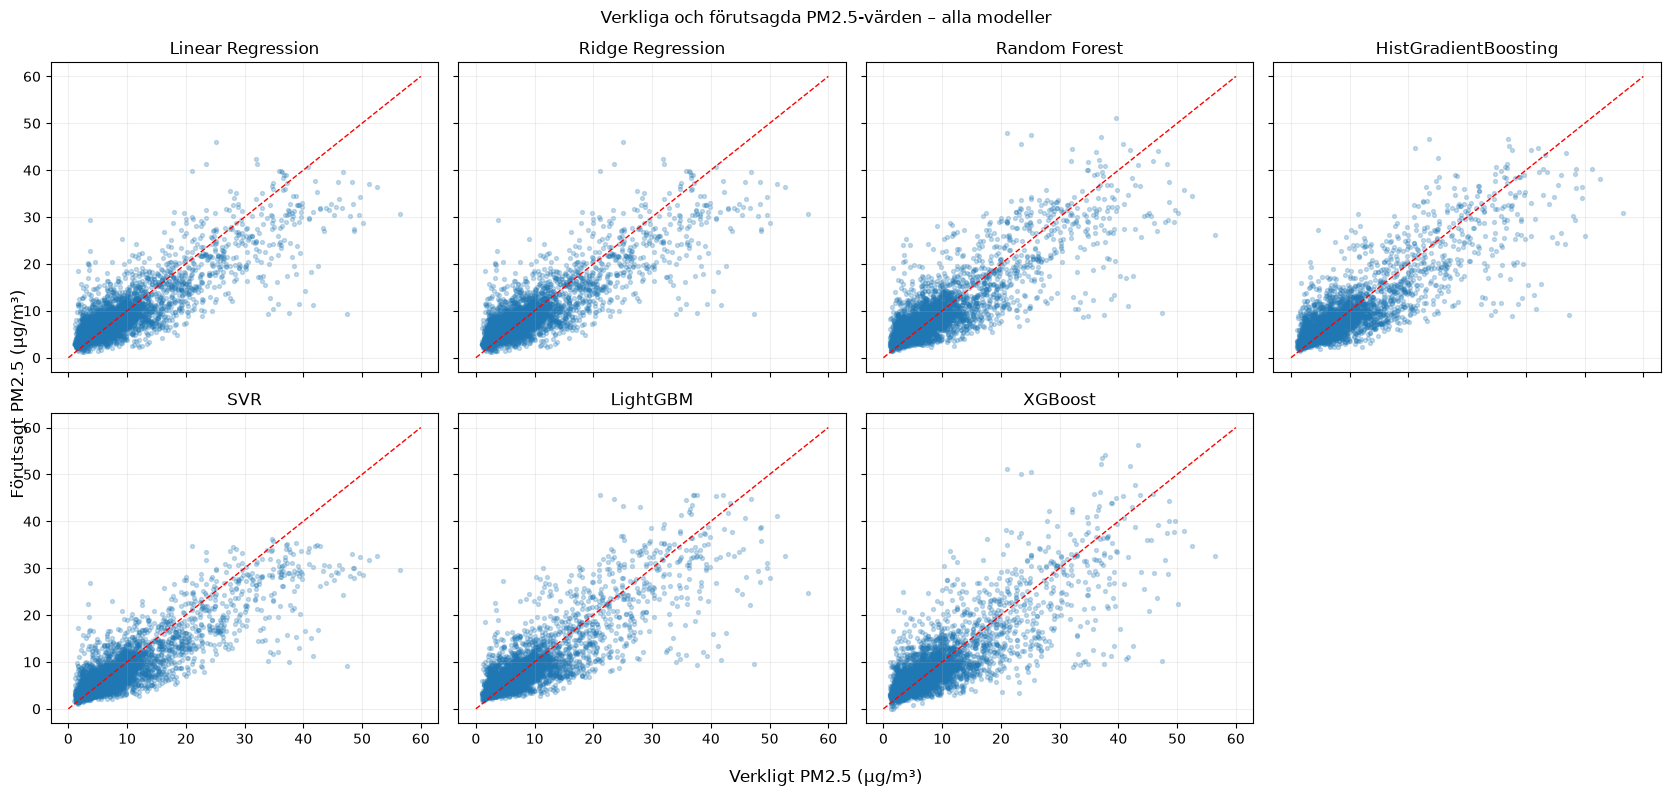

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)

max_value = max(y_val.max(), 60)

for ax, (namn, modell) in zip(axes.flat, trained_models.items()):
    y_pred = modell.predict(X_val)

    ax.scatter(y_val, y_pred, alpha=0.25, s=8)
    ax.plot(
        [0, max_value],
        [0, max_value],
        "r--",
        linewidth=1
    )

    ax.set_title(namn)
    ax.grid(alpha=0.2)

# Dölj den åttonde, tomma rutan
axes.flat[-1].axis("off")

fig.supxlabel("Verkligt PM2.5 (µg/m³)")
fig.supylabel("Förutsagt PM2.5 (µg/m³)")
fig.suptitle("Verkliga och förutsagda PM2.5-värden – alla modeller")

plt.tight_layout()
plt.show()

### Jämförelse av modellernas prognosfel

Samtliga modeller uppvisar ett liknande mönster där låga PM2.5-koncentrationer tenderar att överskattas och höga koncentrationer underskattas. Detta överensstämmer med de negativa Bias-värden som tidigare observerats vid höga koncentrationer.

Även om modellerna skiljer sig åt i prognosprecision och spridning visar ingen modell en tydligt bättre förmåga att hantera de högsta koncentrationerna.

Detta är en viktig begränsning att beakta vid tolkningen av prognoserna och bedömningen av deras användbarhet.

Eftersom mönstret återkommer hos samtliga modeller avslutas analysen av prognosfelen här. Skillnaderna i MAE, RMSE och Bias beaktas i det fortsatta modellvalet.

### Undersöka modellval beroende på om höga värden får en större betydelse

In [33]:
vikt_hoga = 0.40
vikt_alla = 1 - vikt_hoga

ranking_df = results_df[
    ["Modell", "Validation MAE", "Validation High PM2.5 MAE"]
].copy()

# Lägg till persistence baseline
baseline_row = pd.DataFrame([{
    "Modell": "Persistence baseline",
    "Validation MAE": baseline_val_metrics["MAE"],
    "Validation High PM2.5 MAE": baseline_val_metrics["High PM2.5 MAE"]
}])

ranking_df = pd.concat(
    [ranking_df, baseline_row],
    ignore_index=True
)

# Viktad poäng, normaliserad mot baseline
ranking_df["Viktad poäng"] = (
    vikt_alla
    * ranking_df["Validation MAE"]
    / baseline_val_metrics["MAE"]
    +
    vikt_hoga
    * ranking_df["Validation High PM2.5 MAE"]
    / baseline_val_metrics["High PM2.5 MAE"]
)

ranking_df = ranking_df.sort_values("Viktad poäng")

display(ranking_df.round(3))

,Modell,Validation MAE,Validation High PM2.5 MAE,Viktad poäng
3,Linear Regression,2.991,6.399,0.995
4,Ridge Regression,2.991,6.399,0.995
7,Persistence baseline,3.108,6.122,1.000
0,SVR,2.910,6.764,1.004
1,HistGradientBoosting,2.971,6.611,1.005
2,LightGBM,2.978,6.591,1.005
5,Random Forest,3.098,6.421,1.018
6,XGBoost,3.230,7.027,1.083


In [34]:
for vikt_hoga in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    poang = (
        (1 - vikt_hoga)
        * ranking_df["Validation MAE"]
        / baseline_val_metrics["MAE"]
        +
        vikt_hoga
        * ranking_df["Validation High PM2.5 MAE"]
        / baseline_val_metrics["High PM2.5 MAE"]
    )

    vinnare = ranking_df.loc[poang.idxmin(), "Modell"]

    print(f"{vikt_hoga:.0%} vikt höga värden: {vinnare}")

0% vikt höga värden: SVR
20% vikt höga värden: SVR
40% vikt höga värden: Linear Regression
50% vikt höga värden: Persistence baseline
60% vikt höga värden: Persistence baseline
80% vikt höga värden: Persistence baseline
100% vikt höga värden: Persistence baseline


### Känslighetsanalys av modellval

För att undersöka hur viktningen påverkar modellvalet har en sammanvägd poäng beräknats utifrån generell MAE och MAE vid höga PM2.5-koncentrationer, normaliserade mot persistence baseline.

Resultaten visar att SVR presterar bäst när generell prognosprecision prioriteras, medan Linear Regression och Ridge får lägst viktad poäng vid 60/40-fördelning. När höga koncentrationer ges minst 50 % vikt i de undersökta scenarierna presterar persistence baseline bäst.

Modellvalet är därmed känsligt för hur de två måtten viktas. Eftersom skillnaderna dessutom är relativt små finns det inte tillräckligt stöd för att utse en entydig champion utifrån den viktade poängen.

**Slutsats:** SVR, Linear Regression och persistence baseline behålls som kandidater för fortsatt utvärdering. Slutligt modellval bör baseras på prognosernas avsedda användningsområde och ytterligare analys av modellernas stabilitet.

In [24]:
print("Index:", X_val.index)
print("Kolumner:", X_val.columns.tolist())

Index: RangeIndex(start=0, stop=3562, step=1)
Kolumner: ['pm25', 'Lufttemperatur', 'vind_sin', 'vind_cos', 'Vindhastighet', 'Relativ luftfuktighet', 'Nederbördsmängd', 'timme_sin', 'timme_cos', 'helg', 'helg_timme_sin', 'helg_timme_cos']


In [25]:
val_raw = pd.read_csv(cfg.val_processed)

print(val_raw.columns.tolist())
display(val_raw.head(3))

['tid', 'pm25', 'Lufttemperatur', 'Vindriktning', 'Vindhastighet', 'Relativ luftfuktighet', 'Nederbördsmängd', 'vind_sin', 'vind_cos', 'timme_sin', 'timme_cos', 'helg', 'helg_timme_sin', 'helg_timme_cos', 'target']


,tid,pm25,Lufttemperatur,Vindriktning,Vindhastighet,Relativ luftfuktighet,Nederbördsmängd,vind_sin,vind_cos,timme_sin,timme_cos,helg,helg_timme_sin,helg_timme_cos,target
0,2026-01-01 01:00:00+01:00,34.80,2.5,205.0,2.1,97.0,0.1,-0.422618,-0.906308,0.965926,-0.258819,0,0.0,-0.0,3.76
1,2026-01-01 02:00:00+01:00,13.50,3.4,233.0,2.4,98.0,0.8,-0.798636,-0.601815,0.866025,-0.500000,0,0.0,-0.0,1.89
2,2026-01-01 03:00:00+01:00,8.11,4.0,242.0,3.4,98.0,0.0,-0.882948,-0.469472,0.707107,-0.707107,0,0.0,-0.0,3.29


In [26]:
print("Rader i CSV:", len(val_raw))
print("Rader i X_val:", len(X_val))

print("Matchar target:", (
    val_raw["target"].reset_index(drop=True)
    .equals(y_val.reset_index(drop=True))
))

display(val_raw[["tid", "pm25", "target"]].head())

Rader i CSV: 3562
Rader i X_val: 3562
Matchar target: True


,tid,pm25,target
0,2026-01-01 01:00:00+01:00,34.80,3.76
1,2026-01-01 02:00:00+01:00,13.50,1.89
2,2026-01-01 03:00:00+01:00,8.11,3.29
3,2026-01-01 04:00:00+01:00,8.05,3.09
4,2026-01-01 05:00:00+01:00,3.79,2.35


In [27]:
# Prognoser för våra tre kandidater
monthly_df = pd.DataFrame({
    "tid": pd.to_datetime(val_raw["tid"], utc=True),
    "Verkligt": y_val.to_numpy(),
    "SVR": trained_models["SVR"].predict(X_val),
    "Linear Regression": trained_models["Linear Regression"].predict(X_val),
    "Persistence baseline": X_val["pm25"].to_numpy()
})

# Gruppera efter svensk kalendermånad
monthly_df["Månad"] = (
    monthly_df["tid"]
    .dt.tz_convert("Europe/Stockholm")
    .dt.strftime("%Y-%m")
)

# Beräkna absolut prognosfel
for modell in ["SVR", "Linear Regression", "Persistence baseline"]:
    monthly_df[f"{modell} MAE"] = (
        monthly_df["Verkligt"] - monthly_df[modell]
    ).abs()

# Genomsnittligt MAE per månad
monthly_mae = monthly_df.groupby("Månad")[
    ["SVR MAE", "Linear Regression MAE", "Persistence baseline MAE"]
].mean()

display(monthly_mae.round(3))

,SVR MAE,Linear Regression MAE,Persistence baseline MAE
Månad,,,
2026-01,3.347,3.329,3.346
2026-02,2.972,3.123,3.275
2026-03,4.128,4.123,4.159
2026-04,2.132,2.229,2.460
2026-05,1.955,2.147,2.306


In [28]:
monthly_high = monthly_df[
    monthly_df["Verkligt"] >= high_pm25_threshold
]

monthly_high_mae = monthly_high.groupby("Månad")[
    ["SVR MAE", "Linear Regression MAE", "Persistence baseline MAE"]
].mean()

monthly_high_mae["Antal höga värden"] = (
    monthly_high.groupby("Månad").size()
)

display(monthly_high_mae.round(3))

,SVR MAE,Linear Regression MAE,Persistence baseline MAE,Antal höga värden
Månad,,,,
2026-01,6.156,5.436,5.380,215
2026-02,6.525,6.104,6.261,117
2026-03,7.434,7.365,6.622,226
2026-04,6.125,5.993,5.839,33
2026-05,7.908,7.859,7.712,25


In [29]:
monthly_summary = monthly_df.groupby("Månad").agg(
    Antal_observationer=("Verkligt", "size"),
    Antal_höga=("Verkligt", lambda x: (x >= high_pm25_threshold).sum()),
    Medel_PM25=("Verkligt", "mean")
)

monthly_summary["Andel höga (%)"] = (
    100 * monthly_summary["Antal_höga"]
    / monthly_summary["Antal_observationer"]
)

display(monthly_summary.round(2))

,Antal_observationer,Antal_höga,Medel_PM25,Andel höga (%)
Månad,,,,
2026-01,741,215,11.16,29.01
2026-02,624,117,9.49,18.75
2026-03,740,226,14.36,30.54
2026-04,719,33,6.78,4.59
2026-05,738,25,5.40,3.39
